# 02 · Exploratory data analysis

Questions:

1. Are the three sources describing the same market, and can their prices be pooled?
2. Where is housing most expensive, and how do property types compare?
3. How does price scale with size?
4. Which districts form natural market segments?
5. Which combinations of location and property type reliably sit in a high or low price band?

Input: `data/processed/listings_clean.csv` (from notebook 01).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from egypt_real_estate import market, plotting
from egypt_real_estate.cleaning import load_clean
from egypt_real_estate.plotting import PRIMARY, SOURCE_COLORS, egp_formatter

plotting.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

listings = load_clean()
print(f"{len(listings):,} listings")
listings.groupby("source").agg(listings=("price", "size"),
                               median_price=("price", "median"),
                               median_price_per_sqm=("price_per_sqm", "median")).round(0)

62,340 listings


,listings,median_price,median_price_per_sqm
source,,,
Bayut,35058,"9,350,000.00","57,811.00"
Cairo,9071,"4,200,000.00","19,337.00"
OLX,18211,"3,375,000.00","18,089.00"


## 1. The sources are not interchangeable

Before pooling anything, compare the same districts across sources.

Districts with 100+ listings on both sites: 16
Bayut / OLX median price per m²: median ratio 3.3x (range 2.6x to 9.9x)
Rank correlation of district prices between the two sites: 0.38


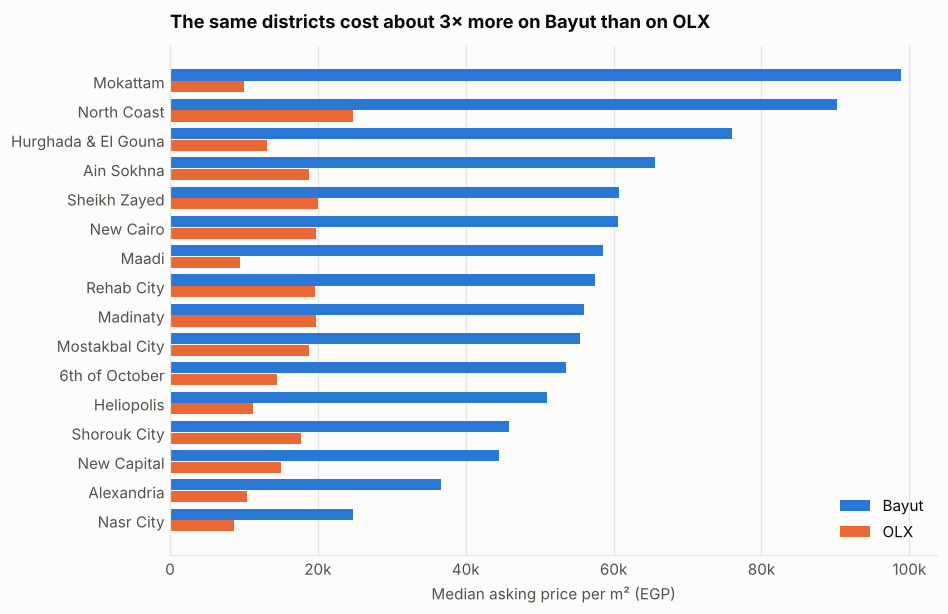

In [2]:
by_source = (listings.groupby(["district", "source"])
             .agg(n=("price", "size"), ppsqm=("price_per_sqm", "median"))
             .unstack("source"))
shared = by_source[(by_source[("n", "Bayut")] >= 100) & (by_source[("n", "OLX")] >= 100)]
shared = shared.sort_values(("ppsqm", "Bayut"))

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(shared))
for src, offset in [("Bayut", 0.2), ("OLX", -0.2)]:
    ax.barh(y + offset, shared[("ppsqm", src)], height=0.38, color=SOURCE_COLORS[src], label=src)
ax.set_yticks(y, shared.index)
ax.xaxis.set_major_formatter(egp_formatter)
ax.set_xlabel("Median asking price per m² (EGP)")
ax.set_title("The same districts cost about 3× more on Bayut than on OLX")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plotting.save(fig, "price_per_sqm_by_source")
plt.show()

ratio = shared[("ppsqm", "Bayut")] / shared[("ppsqm", "OLX")]
rank_corr = shared[("ppsqm", "Bayut")].corr(shared[("ppsqm", "OLX")], method="spearman")
print(f"Districts with 100+ listings on both sites: {len(shared)}")
print(f"Bayut / OLX median price per m²: median ratio {ratio.median():.1f}x "
      f"(range {ratio.min():.1f}x to {ratio.max():.1f}x)")
print(f"Rank correlation of district prices between the two sites: {rank_corr:.2f}")

**Finding.** For the same district, Bayut asking prices per m² run about **3× higher** than OLX,
and the two sites don't even agree on which districts are expensive (low rank correlation).
Two things explain this:

* **Timing.** The OLX and Cairo datasets are older snapshots. The pound lost more than half its
  value against the dollar in 2022–2024, and asking prices rose with it. Bayut is the more recent
  scrape.
* **Mix.** Bayut is dominated by developer and broker listings in new compounds, often off-plan,
  while OLX has more individual resales of older stock. One district name can therefore cover very
  different homes. Mokattam, for example, includes new luxury compounds on Bayut.

**Consequence.** Pooling raw prices from the three sources would describe a market that doesn't
exist. From here on:

* market-level charts use **Bayut only** (the largest and most recent source, 35k listings)
* the price model keeps `source` as a feature, so it learns the level difference instead of being
  confused by it

In [3]:
bayut = listings[listings["source"] == "Bayut"].copy()
print(f"Bayut listings used for the market view: {len(bayut):,}")

Bayut listings used for the market view: 35,058


## 2. Where is it expensive?

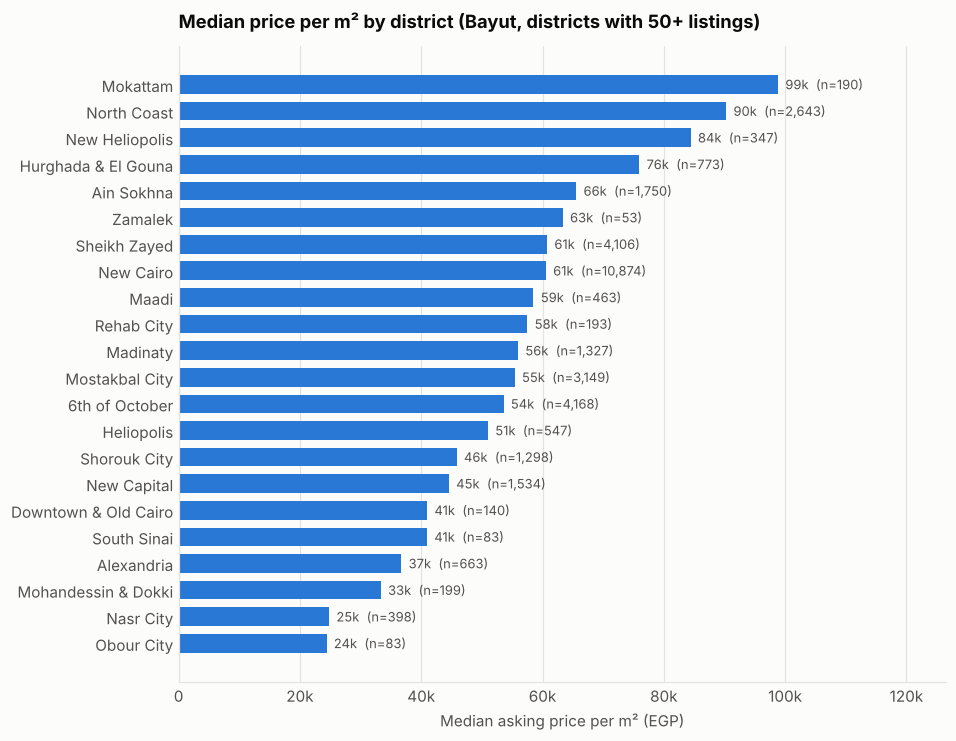

In [4]:
district_stats = (bayut.groupby("district")
                  .agg(listings=("price", "size"), ppsqm=("price_per_sqm", "median"),
                       median_price=("price", "median"))
                  .query("listings >= 50")
                  .sort_values("ppsqm"))

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(district_stats.index, district_stats["ppsqm"], color=PRIMARY, height=0.7)
for i, (v, n) in enumerate(zip(district_stats["ppsqm"], district_stats["listings"])):
    ax.text(v, i, f"  {v / 1000:.0f}k  (n={n:,})", va="center", fontsize=8.5, color=plotting.TEXT_SECONDARY)
ax.xaxis.set_major_formatter(egp_formatter)
ax.set_xlim(0, district_stats["ppsqm"].max() * 1.28)
ax.set_xlabel("Median asking price per m² (EGP)")
ax.set_title("Median price per m² by district (Bayut, districts with 50+ listings)")
ax.grid(axis="y", visible=False)
plotting.save(fig, "price_per_sqm_by_district")
plt.show()

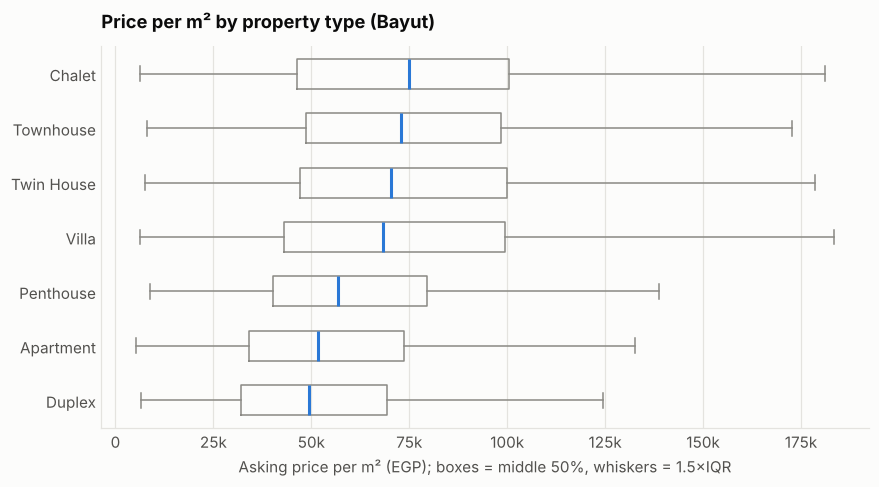

,listings,median_area,median_price,median_ppsqm
type,,,,
Duplex,1567,225.00,"11,000,000.00","49,383.00"
Apartment,19503,152.00,"7,402,212.00","51,667.00"
Penthouse,1018,210.00,"11,300,000.00","56,895.00"
Villa,5858,282.00,"19,000,000.00","68,244.00"
Twin House,1365,285.00,"20,000,000.00","70,317.00"
Townhouse,2521,220.00,"16,000,000.00","72,932.00"
Chalet,3226,116.00,"8,500,000.00","75,000.00"


In [5]:
type_order = bayut.groupby("type")["price_per_sqm"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.5))
data = [bayut.loc[bayut["type"] == t, "price_per_sqm"] for t in type_order]
ax.boxplot(data, vert=False, tick_labels=type_order, showfliers=False, widths=0.55,
           medianprops=dict(color=PRIMARY, linewidth=2),
           boxprops=dict(color=plotting.MUTED), whiskerprops=dict(color=plotting.MUTED),
           capprops=dict(color=plotting.MUTED))
ax.xaxis.set_major_formatter(egp_formatter)
ax.set_xlabel("Asking price per m² (EGP); boxes = middle 50%, whiskers = 1.5×IQR")
ax.set_title("Price per m² by property type (Bayut)")
ax.grid(axis="y", visible=False)
plotting.save(fig, "price_per_sqm_by_type")
plt.show()

bayut.groupby("type").agg(listings=("price", "size"), median_area=("area_sqm", "median"),
                          median_price=("price", "median"),
                          median_ppsqm=("price_per_sqm", "median")).sort_values("median_ppsqm").round(0)

## 3. How does price scale with size?

Elasticity 0.90: a home twice as large costs about 87% more.


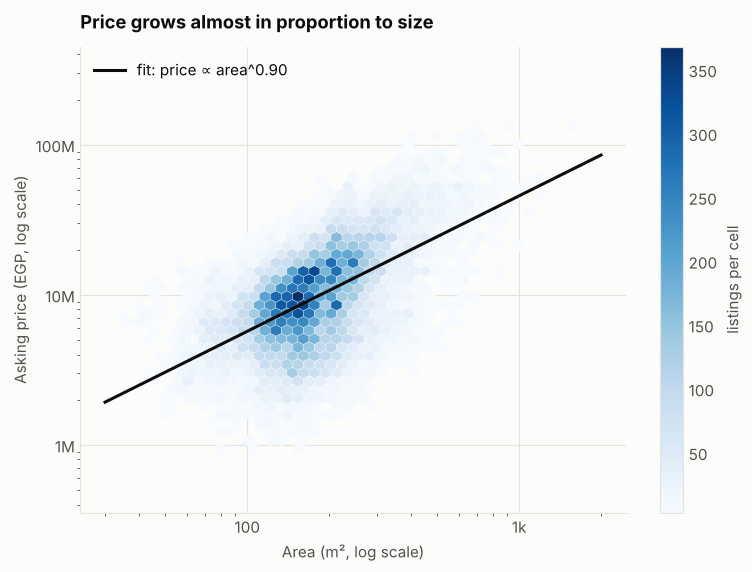

In [6]:
slope, intercept = np.polyfit(np.log(bayut["area_sqm"]), np.log(bayut["price"]), 1)

fig, ax = plt.subplots(figsize=(8, 5.5))
hb = ax.hexbin(bayut["area_sqm"], bayut["price"], xscale="log", yscale="log", gridsize=45,
               cmap="Blues", mincnt=3, linewidths=0.2, edgecolors=plotting.SURFACE)
xs = np.geomspace(bayut["area_sqm"].min(), bayut["area_sqm"].max(), 50)
ax.plot(xs, np.exp(intercept) * xs ** slope, color=plotting.TEXT, linewidth=2,
        label=f"fit: price ∝ area^{slope:.2f}")
ax.yaxis.set_major_formatter(egp_formatter)
ax.xaxis.set_major_formatter(egp_formatter)
ax.set_xlabel("Area (m², log scale)")
ax.set_ylabel("Asking price (EGP, log scale)")
ax.set_title("Price grows almost in proportion to size")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="listings per cell")
plotting.save(fig, "price_vs_area")
plt.show()
print(f"Elasticity {slope:.2f}: a home twice as large costs about {2 ** slope - 1:.0%} more.")

In [7]:
bayut[["price", "price_per_sqm", "area_sqm", "bedrooms", "bathrooms"]].corr(method="spearman").round(2)

,price,price_per_sqm,area_sqm,bedrooms,bathrooms
price,1.00,0.78,0.52,0.41,0.49
price_per_sqm,0.78,1.00,-0.05,-0.07,0.06
area_sqm,0.52,-0.05,1.00,0.81,0.77
bedrooms,0.41,-0.07,0.81,1.00,0.76
bathrooms,0.49,0.06,0.77,0.76,1.00


Area, bedrooms and bathrooms are strongly correlated with each other (0.76–0.81), so they carry
largely the same information. Price per m² is essentially uncorrelated with size: location and
property type set the price level, and size scales it.

## 4. Market segments

Districts are clustered on median price per m², median home size and the share of villas,
townhouses and twin houses (Bayut, districts with 30+ listings). The number of clusters is chosen by
silhouette score.

In [8]:
summary = market.district_summary(bayut, min_listings=30)
segments, silhouette = market.segment_districts(summary)
print("Silhouette score by k:", silhouette.round(3).to_dict())
segment_table = (segments.groupby("segment")
                 .agg(districts=("district", lambda s: ", ".join(s)),
                      median_ppsqm=("median_price_per_sqm", "median"),
                      median_area=("median_area", "median"),
                      villa_share=("share_villas", "median"))
                 .sort_values("median_ppsqm", ascending=False))
pd.set_option("display.max_colwidth", 140)
segment_table.round(2)

Silhouette score by k: {2: 0.327, 3: 0.392, 4: 0.387, 5: 0.365, 6: 0.378}


,districts,median_ppsqm,median_area,villa_share
segment,,,,
Segment 1,"North Coast, Hurghada & El Gouna, Ain Sokhna, Maadi, Madinaty, South Sinai","62,033.50",120.00,0.19
Segment 2,"Mokattam, New Heliopolis, Sheikh Zayed, New Cairo, Rehab City, Mostakbal City, 6th of October, Shorouk City","59,024.00",187.50,0.40
Segment 3,"Zamalek, Heliopolis, New Capital, Downtown & Old Cairo, Alexandria, Mohandessin & Dokki, Nasr City, Obour City, Badr City","36,716.00",170.00,0.01


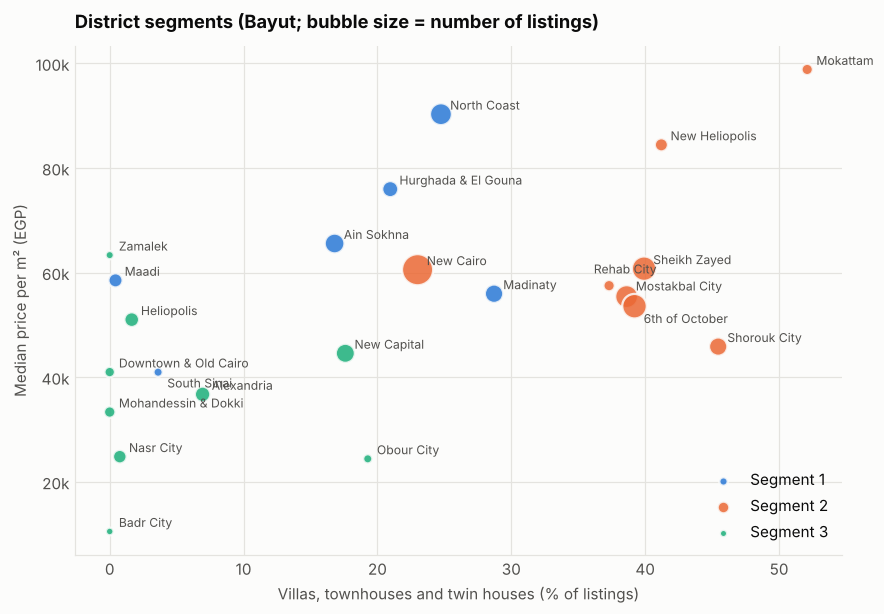

In [9]:
seg_colors = dict(zip(sorted(segments["segment"].unique()), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]))
fig, ax = plt.subplots(figsize=(9, 6))
for seg, grp in segments.groupby("segment"):
    ax.scatter(grp["share_villas"] * 100, grp["median_price_per_sqm"], s=grp["listings"] ** 0.5 * 4,
               color=seg_colors[seg], label=seg, alpha=0.85, edgecolor=plotting.SURFACE, linewidth=1.5)
nudge = {"South Sinai": (6, -10), "Mostakbal City": (6, 4), "6th of October": (6, -11),
         "Rehab City": (-10, 8), "Downtown & Old Cairo": (6, 3)}
for _, row in segments.iterrows():
    ax.annotate(row["district"], (row["share_villas"] * 100, row["median_price_per_sqm"]),
                xytext=nudge.get(row["district"], (6, 3)), textcoords="offset points", fontsize=8, color=plotting.TEXT_SECONDARY)
ax.yaxis.set_major_formatter(egp_formatter)
ax.set_xlabel("Villas, townhouses and twin houses (% of listings)")
ax.set_ylabel("Median price per m² (EGP)")
ax.set_title("District segments (Bayut; bubble size = number of listings)")
ax.legend(loc="lower right", markerscale=0.5)
plotting.save(fig, "district_segments")
plt.show()

Three segments (best silhouette at k = 3). They differ in **what kind of homes** a district offers
as much as in price, so they are numbered rather than labelled luxury or budget:

* **Segment 1, resorts and compact premium markets:** North Coast, Hurghada & El Gouna,
  Ain Sokhna, South Sinai, Maadi, Madinaty. These have the smallest homes (median about 120 m²,
  mostly chalets and apartments) and the highest price per m², about EGP 62k.
* **Segment 2, new-city compound suburbs:** New Cairo, Sheikh Zayed, 6th of October,
  Mostakbal City, Shorouk, Rehab, New Heliopolis, Mokattam. Villas and townhouses make up about 40%
  of listings, homes are larger (about 190 m²), and price per m² is similar to Segment 1, about EGP 59k.
* **Segment 3, established city districts:** Nasr City, Heliopolis, Zamalek, Mohandessin &
  Dokki, Downtown, Alexandria, plus the New Capital, Obour and Badr. Almost no villas, and the
  lowest price per m², about EGP 37k. The New Capital lands here because its Bayut listings are
  mostly apartments priced below the older east-Cairo suburbs.

## 5. Association rules: what predicts a high or low price band?

Each listing gets a **price band** (Low / Medium / High tercile of price per m²). The terciles are
computed *within each source*, so an older OLX listing is compared with other OLX listings and the
3× level gap doesn't distort the rules. Rules have the form `{district, type, bedrooms} → band`
and are mined on the **full cleaned dataset**, not on one raw source.

* **support**: share of all listings matching the rule
* **confidence**: share of matching listings that are in the band
* **lift**: how much more likely the band is than the baseline 1/3

In [10]:
listings["price_band"] = listings.groupby("source")["price_per_sqm"].transform(market.price_bands)
rules = market.association_rules(listings, min_support=0.005, min_confidence=0.6)
print(f"{len(rules)} rules with support >= 0.5% and confidence >= 60%")
fmt = {"support": "{:.3f}", "confidence": "{:.2f}", "lift": "{:.2f}"}
rules.head(12)

15 rules with support >= 0.5% and confidence >= 60%


,antecedent,consequent,count,support,confidence,lift
0,"district=Nasr City, bedrooms=3",price_band=Low,459,0.01,0.89,2.68
1,"district=Nasr City, type=Apartment",price_band=Low,637,0.01,0.87,2.62
2,district=Nasr City,price_band=Low,693,0.01,0.86,2.59
3,"district=Rehab City, type=Apartment",price_band=Medium,334,0.01,0.77,2.31
4,district=Mokattam,price_band=High,449,0.01,0.75,2.25
5,"district=North Coast, type=Townhouse",price_band=High,381,0.01,0.74,2.22
6,"district=Madinaty, type=Apartment",price_band=Medium,984,0.02,0.67,2.00
7,district=Alexandria,price_band=Low,854,0.01,0.64,1.93
8,"district=Alexandria, type=Apartment",price_band=Low,690,0.01,0.64,1.92
9,"district=North Coast, bedrooms=1",price_band=High,353,0.01,0.64,1.92


In [11]:
rules[rules["consequent"] == "price_band=Low"].head(8)

,antecedent,consequent,count,support,confidence,lift
0,"district=Nasr City, bedrooms=3",price_band=Low,459,0.01,0.89,2.68
1,"district=Nasr City, type=Apartment",price_band=Low,637,0.01,0.87,2.62
2,district=Nasr City,price_band=Low,693,0.01,0.86,2.59
7,district=Alexandria,price_band=Low,854,0.01,0.64,1.93
8,"district=Alexandria, type=Apartment",price_band=Low,690,0.01,0.64,1.92
10,"district=Alexandria, bedrooms=3",price_band=Low,471,0.01,0.63,1.88
11,"district=Heliopolis, bedrooms=3",price_band=Low,321,0.01,0.63,1.88


## Key findings

1. **The three sources can't be pooled naively.** Bayut asking prices per m² are about 3.3× OLX's
   for the same districts, and the two sites rank districts differently. Most of the gap is timing:
   the older OLX and Cairo snapshots predate the pound's 2022–2024 devaluation. Listing mix (new
   compounds versus resales) explains the rest. Any model has to account for the source.
2. **Location dominates price per m².** On Bayut, the median ranges from about EGP 25k (Nasr City,
   Obour) to more than EGP 90k (North Coast, Mokattam). In the large markets, New Cairo and
   Sheikh Zayed sit together at about EGP 61k.
3. **Coastal resort homes are the most expensive per m²**, about EGP 75k for chalets, even though
   chalets are the smallest units. Villas, townhouses and twin houses cost 30–40% more per m² than
   apartments.
4. **Price scales almost linearly with size** (elasticity 0.90): a home twice as big costs about
   87% more. Bedrooms and bathrooms add little beyond area because they move together with it.
5. **Location and type together predict the price band well.** Nasr City listings are in the
   lowest tercile 86% of the time, Mokattam in the highest 75% of the time, and North Coast
   townhouses in the highest 74% of the time. These rules feed directly into the recommender's
   explanations in notebook 04.